# Plotting country level mortality per 100K people due to high or low temperatures

Runs over high and low temperatures and calculates yearly mortality

In [1]:
import os
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import SymLogNorm
from matplotlib.colors import Normalize
from matplotlib.ticker import FuncFormatter
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from utils.utils import get_scenario_config
from utils.utils import autosize_figure, land_filter, create_global_country_map
import config
from utils.utils import require_dir
import pathlib

In [2]:
def process_mortality_per_100k(model, scenario, GBD_version, temp, year):
    # === Path config ===
    POP_DIR = require_dir(pathlib.Path(config.WORK_ROOT) / "SSP_pop" / "SSP2")
    MORT_DIR = require_dir(pathlib.Path(config.WORK_ROOT) / model / "mortality" / "temperature" / "gridpoint_mortality")

    # Country level population
    pop_file = "ssp2_era5_country_level_2000-2100.nc"
    pop_path = os.path.join(POP_DIR, pop_file)
    pop = xr.open_dataset(pop_path)["country_population_grid"]

    file = f"Monthly_{temp}_mortality_country_sum_{GBD_version}_{model}_{scenario}_{year}.nc"
    file_path = os.path.join(MORT_DIR, file)
    da = xr.open_dataset(file_path)["country_mortality_grid"]

    da_year = da.sum("month")

    # Calculate population at the selected year
    pop_year = pop.sel(year=year)

    # Calculate mortality per 100,000
    da_per_100k = (da_year/pop_year)*100000
    return da_per_100k

In [5]:
def plot_country_level_mortality_per_100k(da, model, scenario, GBD_version, temp, ens_num, year, vmax, SAVE_DIR):
    # Create figure
    fig = plt.figure(figsize=autosize_figure(1, 1))
    gs = GridSpec(2, 1, height_ratios=[15, 1])  # rows, columns

    # Map set up and design
    projection = ccrs.Robinson()
    crs = ccrs.PlateCarree()

    country_borders = cfeature.NaturalEarthFeature(
        category='cultural',
        name='admin_0_boundary_lines_land',
        scale='50m',
        facecolor='none')

    # Use log scale for normalization
    vmin = da.min().item()
    cmap = plt.get_cmap("magma")

    # Define a linear threshold region around zero
    # linthresh = 1

    norm = Normalize(vmin=vmin, vmax=vmax, clip=False)
    # norm = SymLogNorm(linthresh=linthresh, vmin=vmin, vmax=vmax, base=10)

    # First panel
    ax = fig.add_subplot(gs[0, 0], projection=projection, frameon=True)
    cb = land_filter(da).plot(
        transform=crs,
        add_colorbar=False,
        cmap=cmap,
        norm=norm,
        subplot_kws={'projection': projection}
    )
    ax.coastlines(resolution="50m", linewidth=0.75)
    ax.add_feature(country_borders, edgecolor='k', linewidth=0.75)
    plt.title(f"{temp} temperature mortality \n{model} {scenario} ensemble {ens_num} {year} ")

    # First colorbar
    cax = fig.add_subplot(gs[1, 0])
    col_bar = plt.colorbar(cb, cax=cax, orientation='horizontal')
    col_bar.set_label(f"Total {temp} Temperature Mortality per 100,000 (year$^{-1}$)", fontsize=13)

    # Ticks
    formatter = FuncFormatter(lambda v, _: f"{v:g}")
    col_bar.ax.xaxis.set_major_formatter(formatter)

    # Define custom ticks
    #ticks = [0, 0.5, 1, 5, 10, 50, 100]

    #col_bar.set_ticks(ticks)
    col_bar.ax.xaxis.set_major_formatter(formatter)

    plt.tight_layout()

    out_file = f"{temp}_temperature_mortality_per_100k_country_{GBD_version}_{model}_{scenario}_{ens_num:02d}_{year}.png"
    out_path = os.path.join(SAVE_DIR, out_file)
    plt.savefig(out_path, dpi=300)
    return

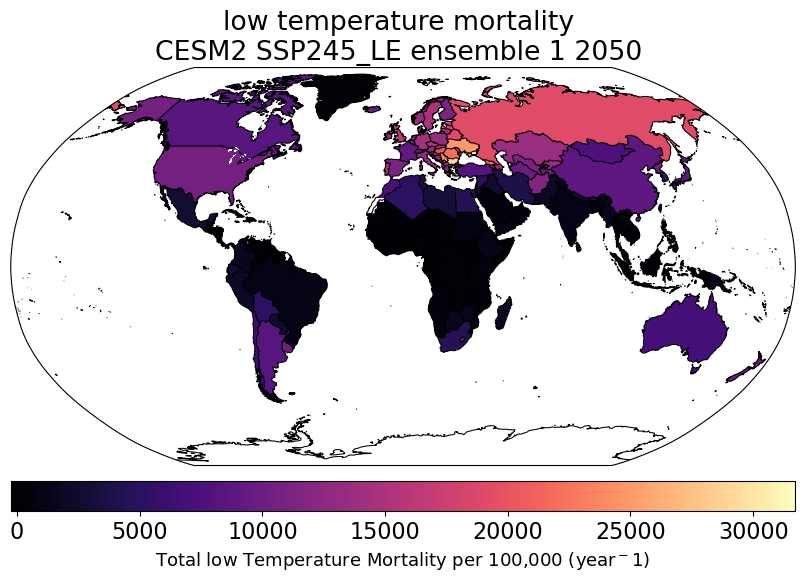

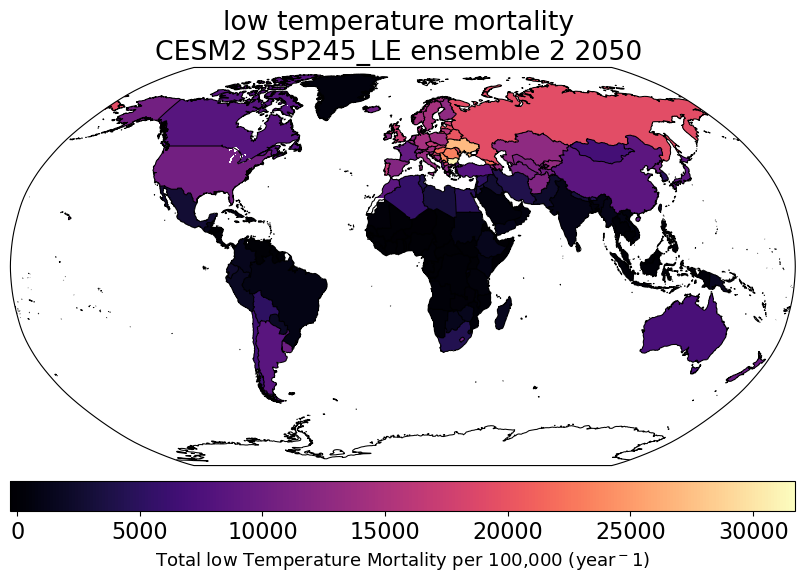

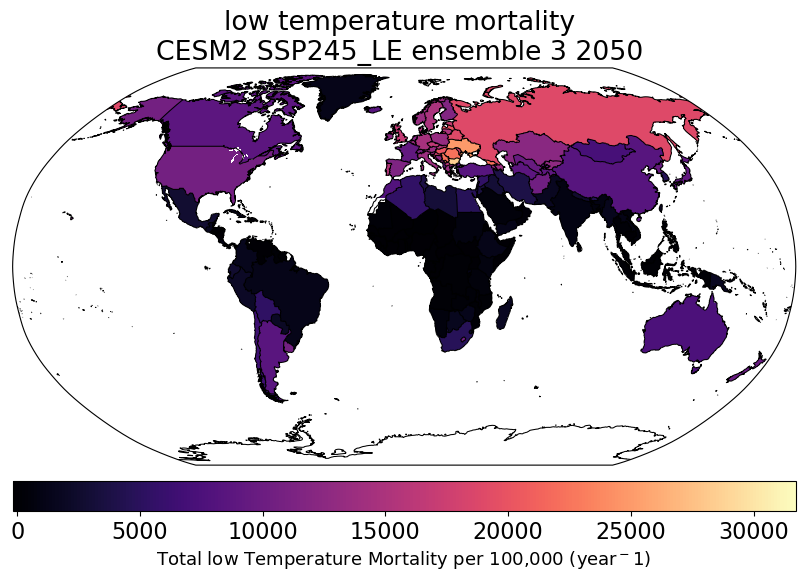

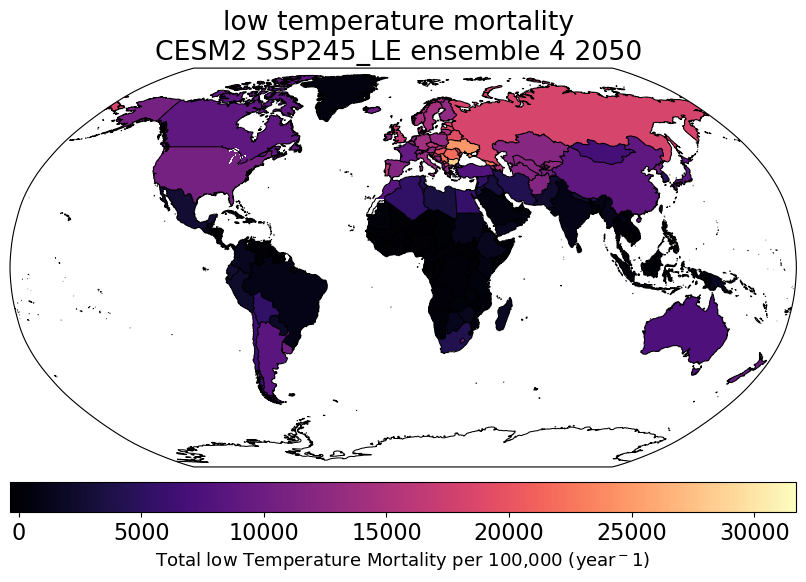

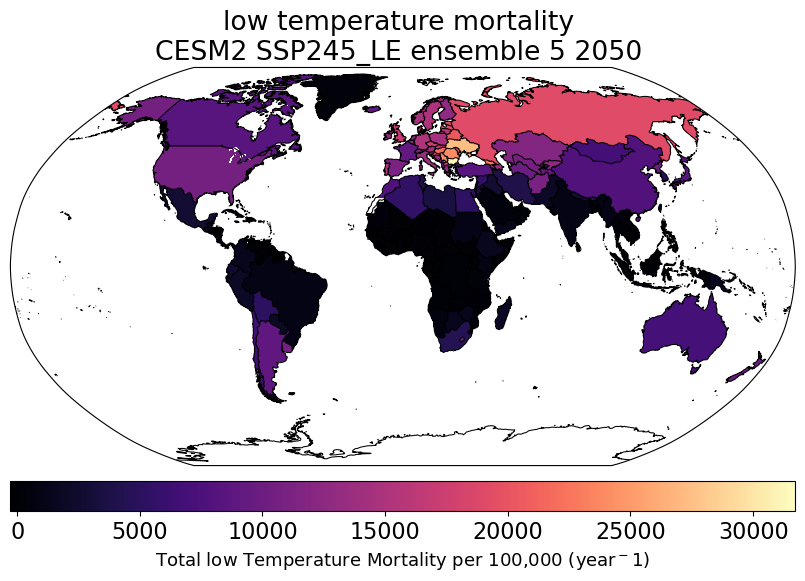

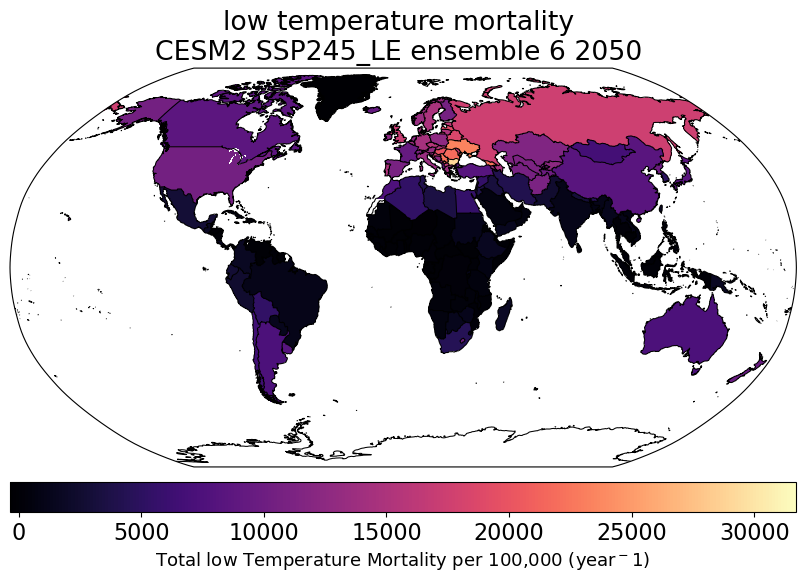

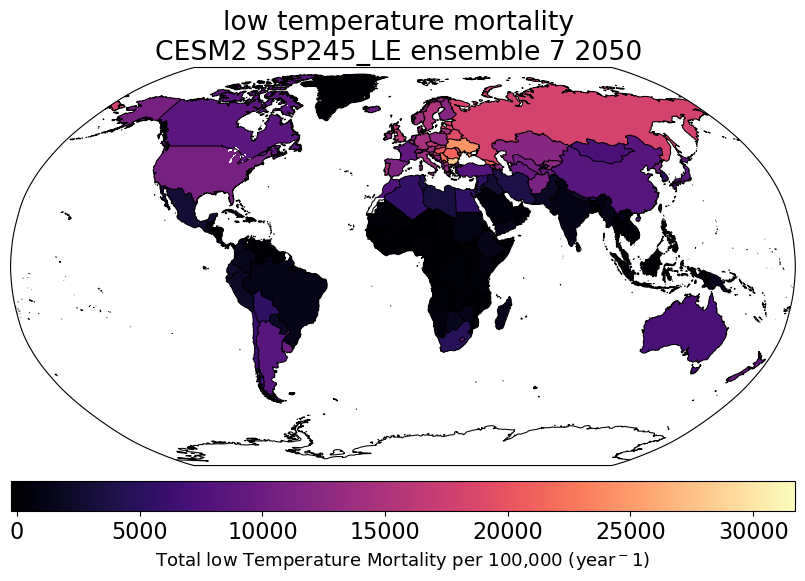

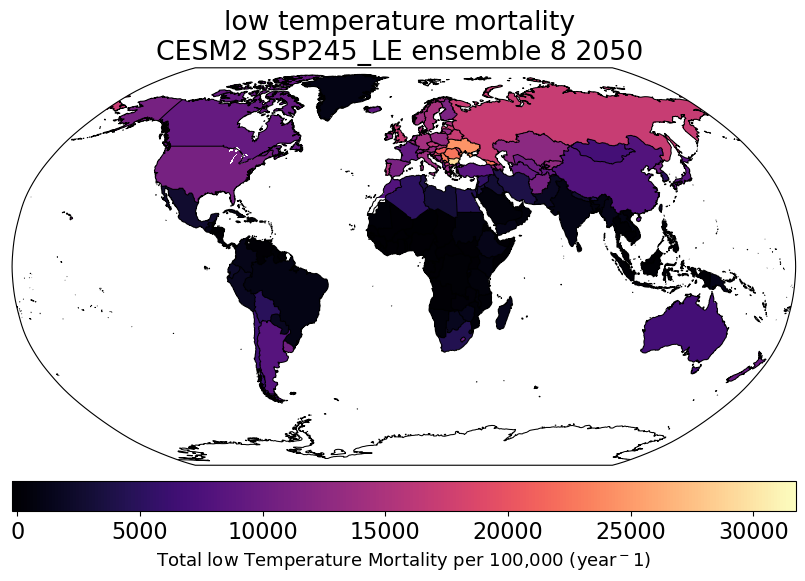

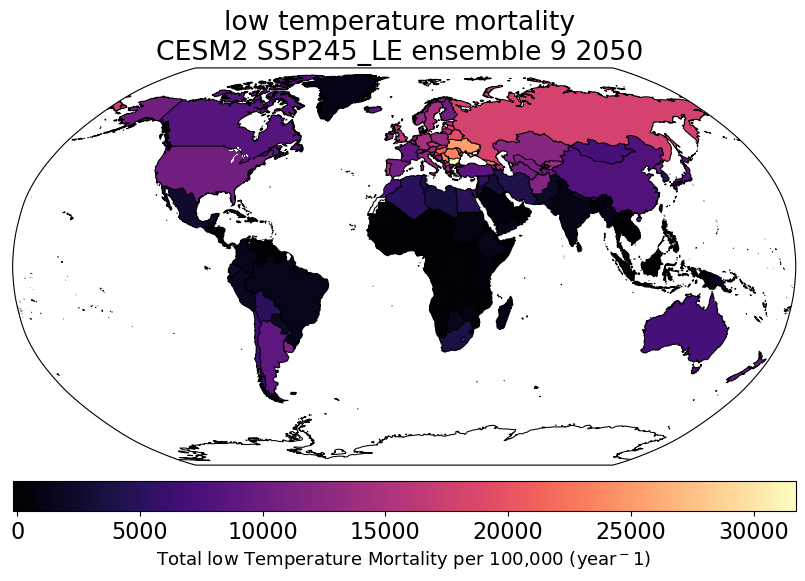

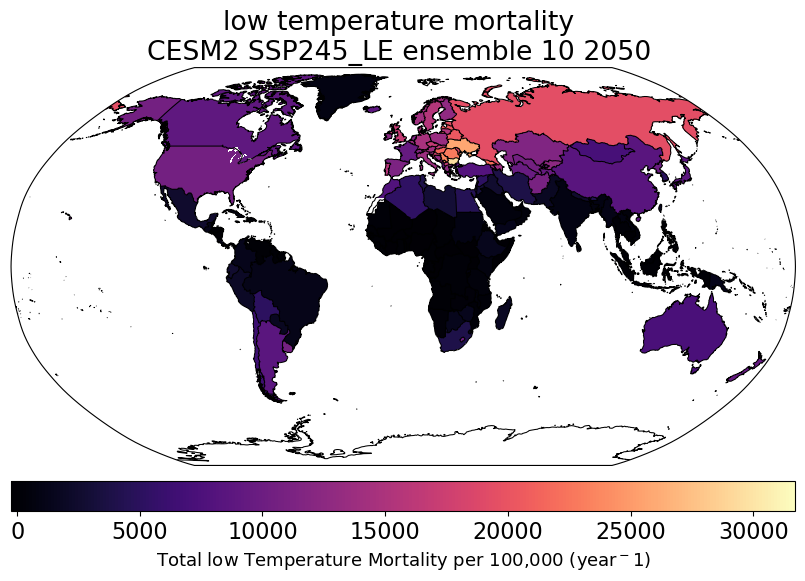

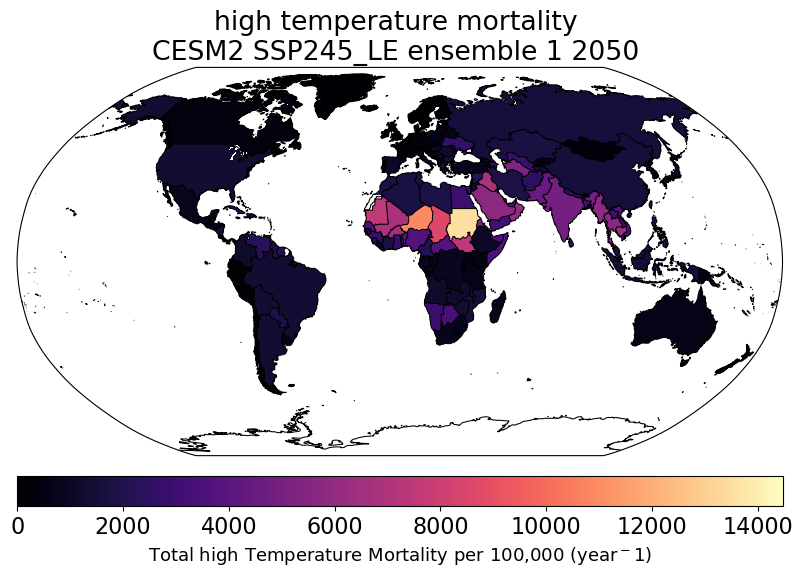

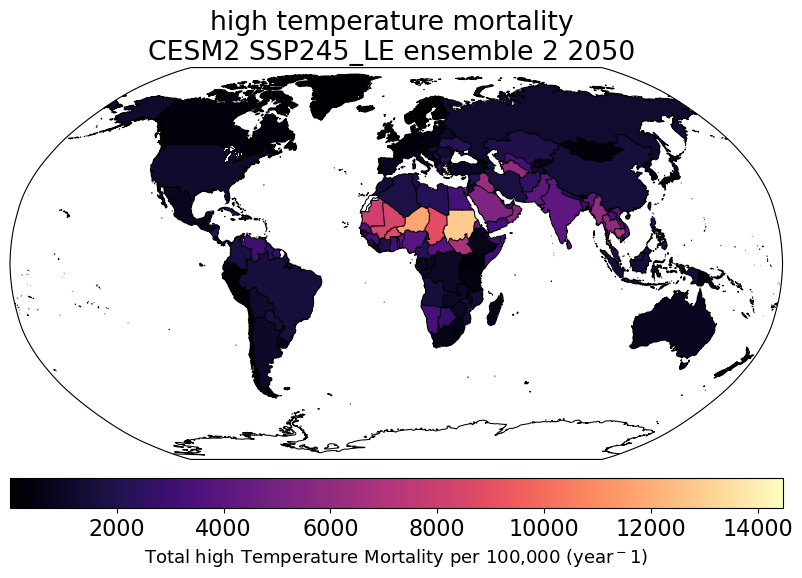

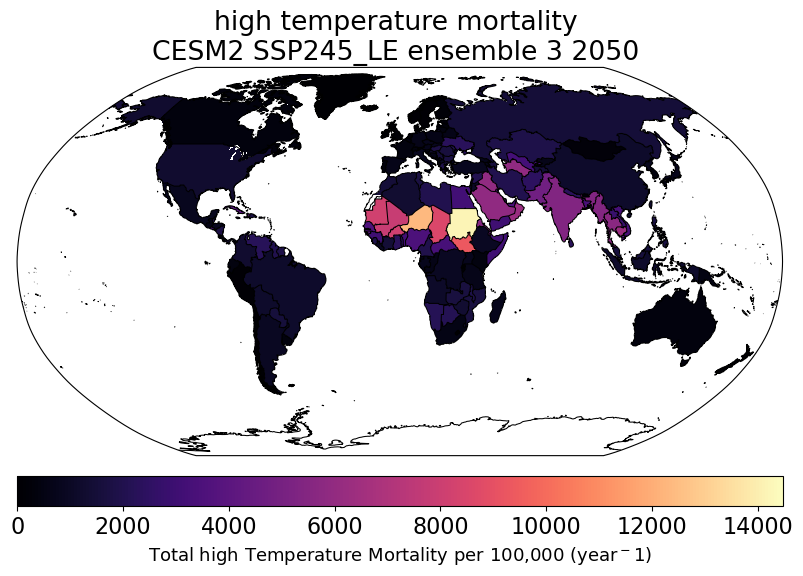

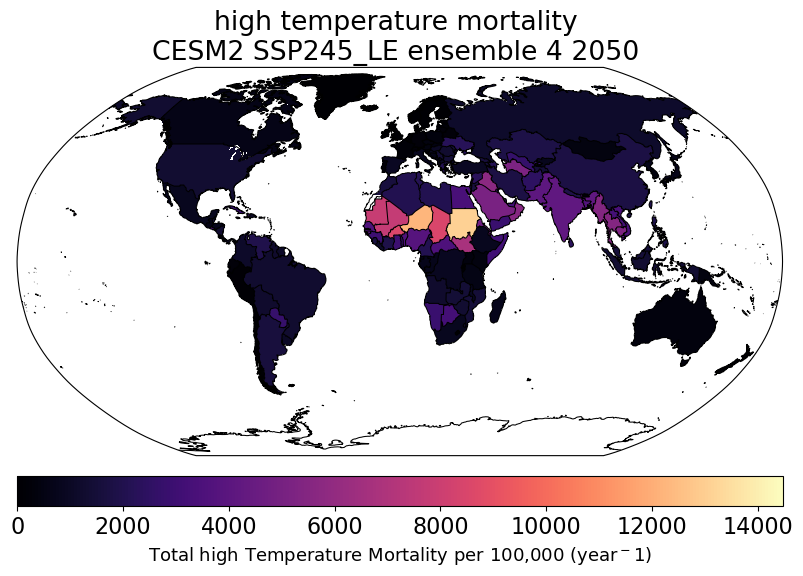

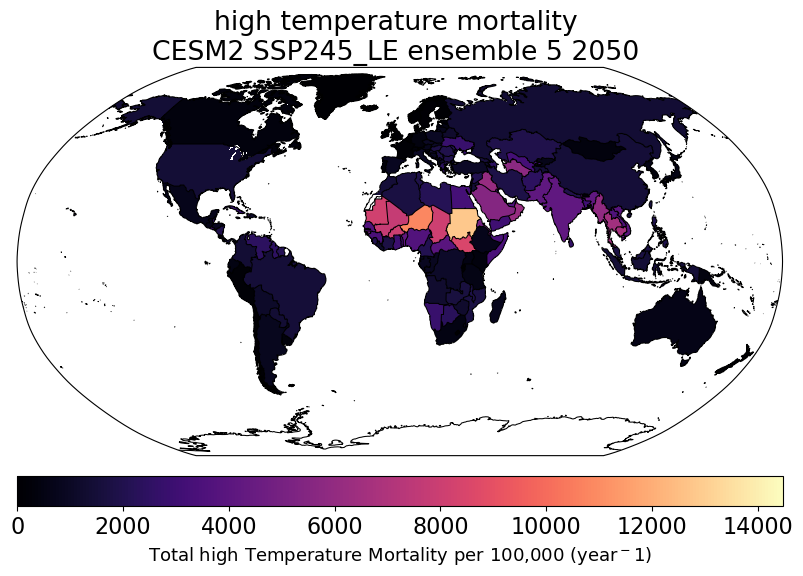

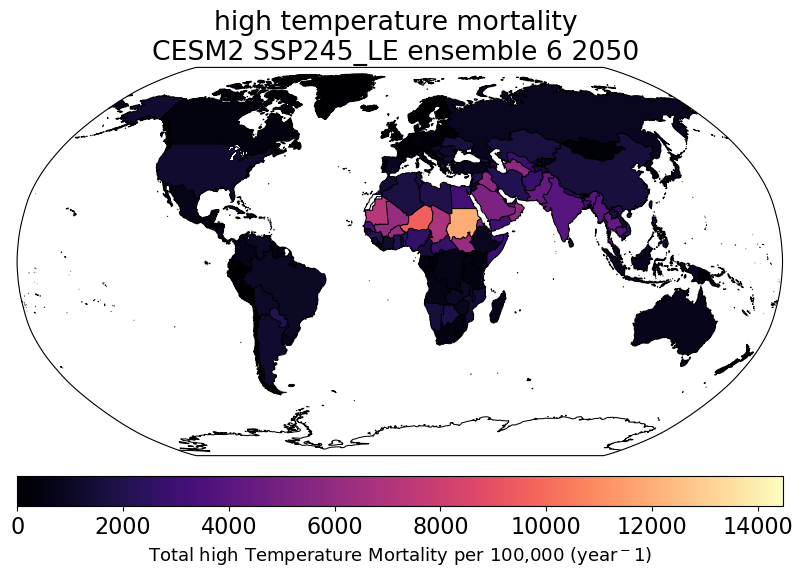

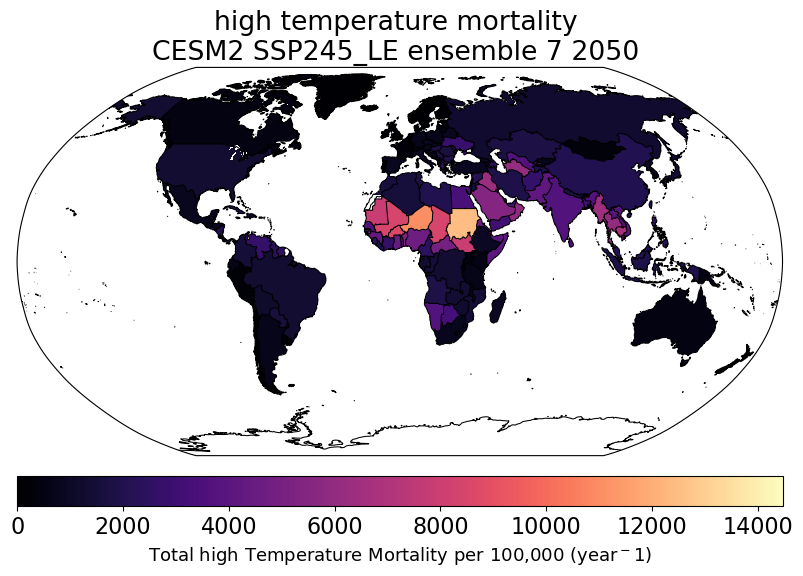

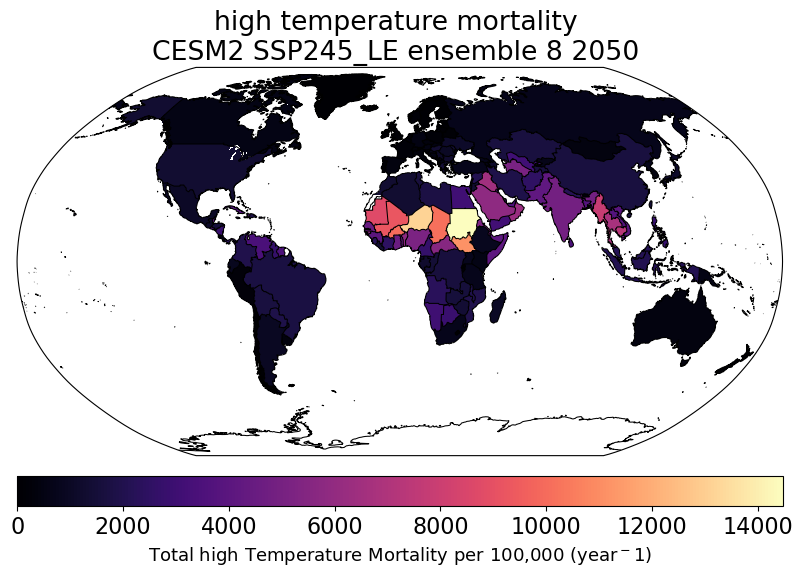

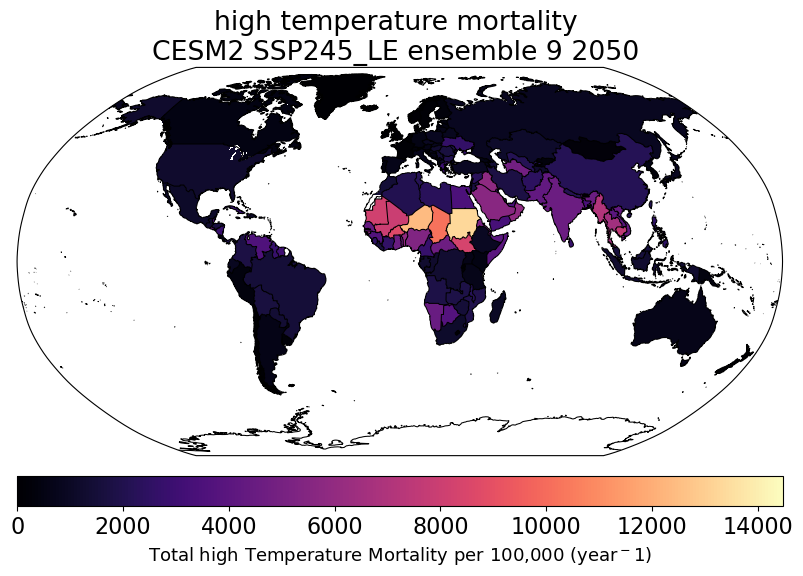

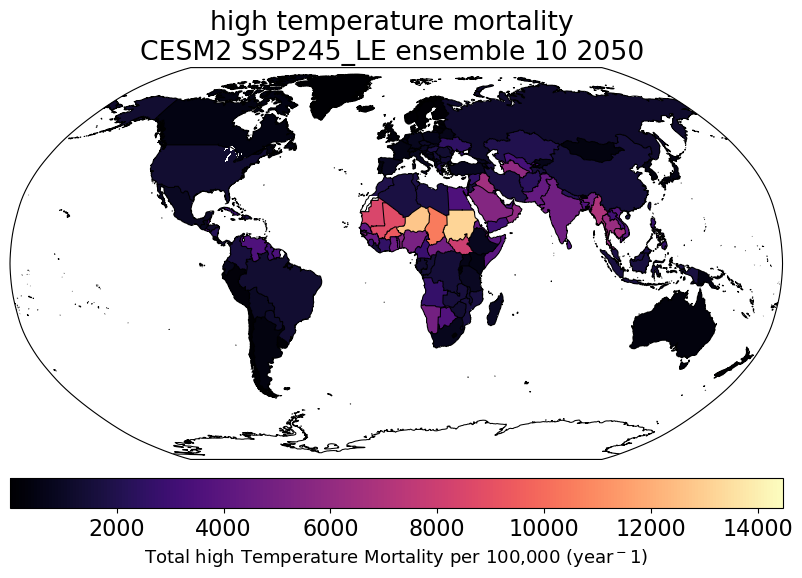

In [6]:
# === Scenario and path config ===
# Set to whatever scenario and model you want
# Function returns error if not recognised
MASK_DIR = require_dir(pathlib.Path(config.WORK_ROOT) / "BMR" / "masks" / "country")
SAVE_DIR = require_dir(pathlib.Path(config.PLOTTING_ROOT) / "mortality" / "temperature")

model = "CESM2"
scenario = "SSP245_LE"
GBD_version = "GBD23"

configs = get_scenario_config(model, scenario)
ensemble_members = configs["ensemble_members"]

plotting_year = 2050

for temp, hl in ["cold", "low"], ["heat", "high"]:
    # Calculate yearly mortality per 100k
    da = process_mortality_per_100k(model, scenario, GBD_version, temp, plotting_year)
    vmax = da.max().item()
    for ens_num in ensemble_members:
        # Plotting
        plt.rcParams.update({'font.size': 16})
        plot_country_level_mortality_per_100k(da.sel(ensemble=ens_num), model, scenario, GBD_version, hl, ens_num, plotting_year, vmax, SAVE_DIR)